# Decision Transformer en GPU: entrenamiento y búsqueda de hiperparámetros

Este notebook:
1. Entrena varios DT con **búsqueda aleatoria** de hiperparámetros.
2. Elige la configuración con el **protocolo en validación** (no con la pérdida).
3. Reentrena la mejor configuración con **3 semillas**.
4. Compara con las líneas base y deja el test **reservado** (`RUN_TEST = False`).

Requisitos: ejecutar desde `2026/tp` con el entorno del TP instalado. Pensado para una VM con GPU NVIDIA A30 (24 GB), 128 cores y 396 GB de RAM: usa AMP (fp16), TF32 y batches grandes. El entrenamiento es rápido; el costo principal es la evaluación secuencial del protocolo (un forward batch-1 por paso de sesión). En CPU funciona igual pero tarda mucho más.

Para una prueba rápida de punta a punta, poner `SMOKE = True` en la próxima celda.

In [1]:
SMOKE = False

DATASET = "netflix"
HORIZON = 20
RUN_NAME = "dt_gpu_smoke" if SMOKE else "dt_gpu"

HPO_TRIALS = 1 if SMOKE else 12
HPO_PER_GROUP = 2 if SMOKE else 25
HPO_TARGETS = [89] if SMOKE else [81, 89, 97]
HPO_CONDITIONS = [(0, True), (0, False)]
MAX_BATCHES = 3 if SMOKE else None

FINAL_SEEDS = (0,) if SMOKE else (0, 1, 2)
FINAL_PER_GROUP = 2 if SMOKE else 50
FINAL_TARGETS = [89] if SMOKE else [65, 81, 89, 97]
EVAL_SEEDS = (0,) if SMOKE else (0, 1, 2)

RUN_TEST = False

In [2]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = Path.cwd()
if not (ROOT / "config_dataset.py").exists():
    raise RuntimeError("Ejecutar el notebook desde 2026/tp")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from modelos.dt import DTPolicy
from modelos.entrenamiento import train_dt
from protocolo.datos import load_test, load_train, make_episodes, num_items, split_by_user
from protocolo.evaluar import baseline_factories, evaluate, write_reports
from protocolo.metricas import summarize
from protocolo.simulador import SessionConfig

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"
if DEVICE == "cuda":
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.set_float32_matmul_precision("high")

torch.manual_seed(0)
np.random.seed(0)
print(f"torch {torch.__version__} | device: {DEVICE} | amp: {USE_AMP}")
if DEVICE == "cuda":
    print(torch.cuda.get_device_name(0))
if SMOKE:
    print("MODO SMOKE: corrida corta para validar el notebook")

torch 2.15.0+cu132 | device: cuda | amp: True
NVIDIA A30


In [3]:
paths = Path(f"outputs/{RUN_NAME}")
paths.mkdir(parents=True, exist_ok=True)

train_all = load_train(DATASET)
train, val = split_by_user(train_all)
N_ITEMS = num_items(DATASET)
train_ep = make_episodes(train, HORIZON)
val_ep = make_episodes(val, HORIZON)


def stratified_subset(users, per_group, seed=0):
    rng = np.random.default_rng(seed)
    subset = []
    for group in range(8):
        members = [u for u in users if u.group == group]
        take = min(per_group, len(members))
        idx = rng.choice(len(members), size=take, replace=False)
        subset.extend(members[i] for i in idx)
    return subset


hpo_users = stratified_subset(val, HPO_PER_GROUP, seed=0)
final_users = stratified_subset(val, FINAL_PER_GROUP, seed=1)

print(f"catálogo: {N_ITEMS} ítems")
print(f"episodios: train {train_ep.items.shape[0]:,} | val {val_ep.items.shape[0]:,}")
print(f"usuarios de val: HPO {len(hpo_users)} | final {len(final_users)}")

catálogo: 752 ítems
episodios: train 73,827 | val 8,275
usuarios de val: HPO 200 | final 400


## 1. Búsqueda de hiperparámetros

Búsqueda aleatoria sobre `d_model`, `n_layers`, `n_heads`, `dropout`, `lr`, `weight_decay`, `group_dropout`, `batch_size` y `epochs`.

Cada trial se entrena una vez y se evalúa en un subconjunto estratificado de validación (25 usuarios por grupo) con el protocolo: warm-up 0, grupo visible y oculto, y varios retornos pedidos dentro del soporte de train. El score es el **normalizado medio** de las dos condiciones con el mejor retorno pedido del trial.

En la A30 el entrenamiento de cada trial es rápido; el tiempo lo domina la evaluación del protocolo, que hace un forward batch-1 por paso de sesión. Si hace falta acortar, bajar `HPO_TRIALS` o `HPO_PER_GROUP`.

La cross-entropy se guarda sólo como diagnóstico: con logs uniformes queda cerca de `log(n_items)` y **no mide calidad** (rúbrica). La selección final se hace sobre otra muestra de validación (semilla distinta) y se reportan media y desvío entre semillas de entrenamiento.

In [4]:
rng = np.random.default_rng(123)


def sample_config():
    d_model = int(rng.choice([128, 192, 256]))
    head_options = [h for h in (4, 8) if d_model % h == 0]
    return {
        "d_model": d_model,
        "n_heads": int(rng.choice(head_options)),
        "n_layers": int(rng.choice([2, 3, 4])),
        "dropout": float(rng.choice([0.0, 0.1, 0.2])),
        "lr": float(np.exp(rng.uniform(np.log(3e-4), np.log(2e-3)))),
        "weight_decay": float(rng.choice([1e-2, 1e-1])),
        "group_dropout": float(rng.choice([0.0, 0.3])),
        "batch_size": int(rng.choice([512, 1024, 2048])),
        "epochs": int(rng.choice([20, 30, 40])),
    }


def evaluate_dt(model, users, targets, conditions, seeds):
    rows = []
    for target in targets:
        policy = DTPolicy(model, target_return=target)
        for warmup, visible in conditions:
            cfg = SessionConfig(horizon=HORIZON, warmup=warmup, group_visible=visible)
            s = summarize(evaluate(policy, users, N_ITEMS, cfg, seeds=seeds))
            rows.append({
                "target": target,
                "warmup": warmup,
                "visible": visible,
                "normalized": float(s[("normalized", "mean")].iloc[0]),
                "ci95": float(s[("normalized", "ci95")].iloc[0]),
                "return": float(s[("return", "mean")].iloc[0]),
                "hit_rate": float(s[("hit_rate", "mean")].iloc[0]),
            })
    return pd.DataFrame(rows)

In [5]:
SMOKE_CONFIG = {
    "d_model": 32, "n_heads": 2, "n_layers": 1, "dropout": 0.0,
    "lr": 1e-3, "weight_decay": 1e-2, "group_dropout": 0.3,
    "batch_size": 32, "epochs": 1,
}

hpo_rows = []
for trial in range(HPO_TRIALS):
    cfg = SMOKE_CONFIG if SMOKE else sample_config()
    start = time.time()
    model, history, val_ce = train_dt(
        train_ep, val_ep, N_ITEMS,
        seed=0,
        max_batches=MAX_BATCHES,
        device=DEVICE,
        amp=USE_AMP,
        output=paths / "hpo" / f"trial{trial:02d}",
        verbose=not SMOKE,
        **cfg,
    )
    scores = evaluate_dt(model, hpo_users, HPO_TARGETS, HPO_CONDITIONS, seeds=(0,))
    per_target = scores.groupby("target")["normalized"].mean()
    target = float(per_target.idxmax())
    score = float(per_target.max())
    row = {**cfg, "target": target, "score": score, "val_ce": val_ce,
           "minutos": (time.time() - start) / 60}
    hpo_rows.append(row)
    print(f"trial {trial}: score={score:.3f} | target={target:.0f} | ce={val_ce:.4f} "
          f"| {row['minutos']:.1f} min | {cfg}")
    del model
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

hpo = pd.DataFrame(hpo_rows).sort_values("score", ascending=False).reset_index(drop=True)
hpo.to_csv(paths / "hpo_resultados.csv", index=False)
hpo.round(4)

epoch   1/20 | train 6.6229 | val 6.6148 | mejor 6.6148 | lr 4.77e-05
epoch   2/20 | train 6.6116 | val 6.6109 | mejor 6.6109 | lr 1.28e-04
epoch   3/20 | train 6.6109 | val 6.6115 | mejor 6.6109 | lr 2.38e-04
epoch   4/20 | train 6.6113 | val 6.6114 | mejor 6.6109 | lr 3.47e-04
epoch   5/20 | train 6.6102 | val 6.6111 | mejor 6.6109 | lr 4.27e-04
epoch   6/20 | train 6.6041 | val 6.5986 | mejor 6.5986 | lr 4.56e-04
epoch   7/20 | train 6.5966 | val 6.5928 | mejor 6.5928 | lr 4.50e-04
epoch   8/20 | train 6.5923 | val 6.5898 | mejor 6.5898 | lr 4.33e-04
epoch   9/20 | train 6.5893 | val 6.5889 | mejor 6.5889 | lr 4.06e-04
epoch  10/20 | train 6.5874 | val 6.5945 | mejor 6.5889 | lr 3.69e-04
epoch  11/20 | train 6.5862 | val 6.5875 | mejor 6.5875 | lr 3.26e-04
epoch  12/20 | train 6.5844 | val 6.5884 | mejor 6.5875 | lr 2.78e-04
epoch  13/20 | train 6.5833 | val 6.5889 | mejor 6.5875 | lr 2.27e-04
epoch  14/20 | train 6.5823 | val 6.5880 | mejor 6.5875 | lr 1.76e-04
epoch  15/20 | train

,d_model,n_heads,n_layers,dropout,lr,weight_decay,group_dropout,batch_size,epochs,target,score,val_ce,minutos
0,128,4,3,0.2,0.0010,0.01,0.0,1024,40,97.0,0.5658,6.5801,2.3016
1,128,8,2,0.0,0.0014,0.10,0.0,1024,40,97.0,0.5588,6.5877,1.8892
2,192,8,3,0.2,0.0005,0.10,0.3,2048,40,97.0,0.5527,6.5880,3.0311
3,192,4,3,0.2,0.0015,0.10,0.0,1024,30,97.0,0.5522,6.5796,2.4007
4,192,4,3,0.1,0.0005,0.10,0.3,2048,20,97.0,0.5516,6.5900,1.7799
5,256,4,3,0.0,0.0003,0.01,0.0,2048,30,97.0,0.5508,6.5893,2.4589
6,128,8,3,0.2,0.0005,0.10,0.3,512,30,97.0,0.5478,6.5863,2.2260
7,128,8,3,0.0,0.0005,0.01,0.0,1024,20,97.0,0.5469,6.5874,1.7168
8,256,4,2,0.0,0.0003,0.01,0.0,1024,30,97.0,0.5467,6.5909,1.9102
9,192,8,3,0.2,0.0005,0.01,0.3,512,40,97.0,0.5420,6.5874,3.3189


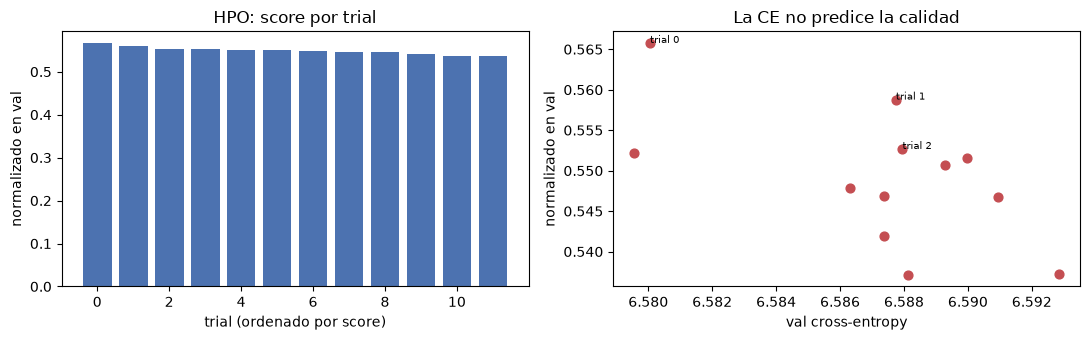

Mejor configuración:


,0
d_model,128.000000
n_heads,4.000000
n_layers,3.000000
dropout,0.200000
lr,0.000966
weight_decay,0.010000
group_dropout,0.000000
batch_size,1024.000000
epochs,40.000000
target,97.000000


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].bar(np.arange(len(hpo)), hpo["score"], color="#4c72b0")
axes[0].set_xlabel("trial (ordenado por score)")
axes[0].set_ylabel("normalizado en val")
axes[0].set_title("HPO: score por trial")

axes[1].scatter(hpo["val_ce"], hpo["score"], s=40, color="#c44e52")
axes[1].set_xlabel("val cross-entropy")
axes[1].set_ylabel("normalizado en val")
axes[1].set_title("La CE no predice la calidad")
for idx, row in hpo.head(3).iterrows():
    axes[1].annotate(f"trial {idx}", (row["val_ce"], row["score"]), fontsize=7)
plt.tight_layout()
plt.show()

print("Mejor configuración:")
display(hpo.head(1).T)

## 2. Entrenamiento final con la mejor configuración

Se reentrena la configuración ganadora con 3 semillas. Cada semilla guarda `modelo.pt`, `config.json` e `historial.csv` en `outputs/<RUN_NAME>/final/seed<k>/`.

In [9]:
best = hpo.iloc[0]
integer_keys = {"d_model", "n_heads", "n_layers", "batch_size", "epochs"}
best_cfg = {
    key: int(best[key]) if key in integer_keys else float(best[key])
    for key in ["d_model", "n_heads", "n_layers", "dropout", "lr",
                "weight_decay", "group_dropout", "batch_size", "epochs"]
}
print("Configuración final:", best_cfg)

models, histories = {}, {}
for seed in FINAL_SEEDS:
    model, history, val_ce = train_dt(
        train_ep, val_ep, N_ITEMS,
        seed=seed,
        max_batches=MAX_BATCHES,
        device=DEVICE,
        amp=USE_AMP,
        output=paths / "final" / f"seed{seed}",
        **best_cfg,
    )
    models[seed] = model
    histories[seed] = history

Configuración final: {'d_model': 128, 'n_heads': 4, 'n_layers': 3, 'dropout': 0.2, 'lr': 0.0009661705275750276, 'weight_decay': 0.01, 'group_dropout': 0.0, 'batch_size': 1024, 'epochs': 40}
epoch   1/40 | train 6.6210 | val 6.6123 | mejor 6.6123 | lr 5.45e-05
epoch   2/40 | train 6.6124 | val 6.6107 | mejor 6.6107 | lr 1.01e-04
epoch   3/40 | train 6.6118 | val 6.6110 | mejor 6.6107 | lr 1.75e-04
epoch   4/40 | train 6.6121 | val 6.6114 | mejor 6.6107 | lr 2.71e-04
epoch   5/40 | train 6.6122 | val 6.6116 | mejor 6.6107 | lr 3.83e-04
epoch   6/40 | train 6.6119 | val 6.6096 | mejor 6.6096 | lr 5.03e-04
epoch   7/40 | train 6.6095 | val 6.6076 | mejor 6.6076 | lr 6.23e-04
epoch   8/40 | train 6.6046 | val 6.5960 | mejor 6.5960 | lr 7.35e-04
epoch   9/40 | train 6.5985 | val 6.5924 | mejor 6.5924 | lr 8.31e-04
epoch  10/40 | train 6.5947 | val 6.6061 | mejor 6.5924 | lr 9.05e-04
epoch  11/40 | train 6.5928 | val 6.5881 | mejor 6.5881 | lr 9.51e-04
epoch  12/40 | train 6.5902 | val 6.5876

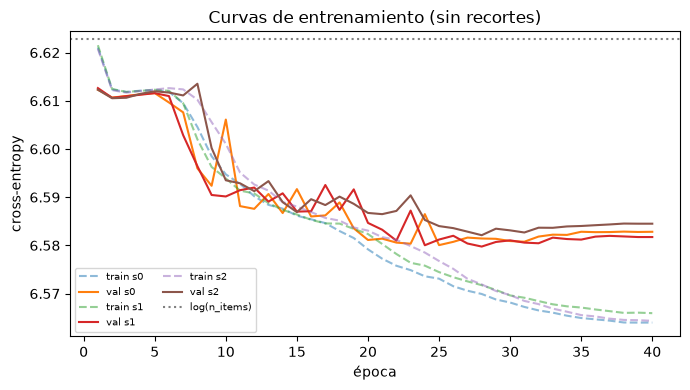

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
for seed, history in histories.items():
    ax.plot(history["epoch"], history["train_loss"], "--", alpha=0.5, label=f"train s{seed}")
    ax.plot(history["epoch"], history["val_loss"], "-", label=f"val s{seed}")
ax.axhline(np.log(N_ITEMS), color="gray", ls=":", label="log(n_items)")
ax.set_xlabel("época")
ax.set_ylabel("cross-entropy")
ax.set_title("Curvas de entrenamiento (sin recortes)")
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

## 3. Evaluación en validación

Se barre el retorno pedido y las 4 condiciones (warm-up 0/5 × grupo visible/oculto) con las 3 semillas de entrenamiento. El retorno final se elige por **normalizado medio en validación**, dentro del soporte de train. También se evalúan las líneas base sobre los mismos usuarios.

In [11]:
conditions = [(0, True), (0, False), (5, True), (5, False)]

rows = []
for seed, model in models.items():
    df = evaluate_dt(model, final_users, FINAL_TARGETS, conditions, EVAL_SEEDS)
    df["seed"] = seed
    rows.append(df)
val_dt = pd.concat(rows, ignore_index=True)
val_dt.to_csv(paths / "dt_val_barrido.csv", index=False)

by_target = val_dt.groupby("target")["normalized"].mean().sort_values(ascending=False)
print("Normalizado medio por retorno pedido (todas las condiciones y semillas):")
print(by_target.round(3).to_string())
best_target = float(by_target.index[0])

chosen = val_dt[val_dt["target"] == best_target]
print(f"\nDT con objetivo {best_target:.0f}: normalizado por semilla")
display(chosen.pivot_table(index="seed", columns=["warmup", "visible"], values="normalized").round(3))

print("Media y desvío entre semillas de entrenamiento:")
display(chosen.groupby(["warmup", "visible"])["normalized"].agg(["mean", "std"]).round(3))

Normalizado medio por retorno pedido (todas las condiciones y semillas):
target
97    0.577
89    0.545
81    0.410
65   -0.069

DT con objetivo 97: normalizado por semilla


warmup       0             5       
visible  False  True   False  True 
seed                               
0        0.546  0.596  0.565  0.608
1        0.553  0.591  0.565  0.601
2        0.548  0.585  0.569  0.594

Media y desvío entre semillas de entrenamiento:


mean    std
warmup visible              
0      False    0.549  0.004
       True     0.591  0.006
5      False    0.566  0.002
       True     0.601  0.007

In [12]:
base_rows = []
for name, factory in baseline_factories(train, N_ITEMS).items():
    for warmup, visible in conditions:
        cfg = SessionConfig(horizon=HORIZON, warmup=warmup, group_visible=visible)
        s = summarize(evaluate(factory(), final_users, N_ITEMS, cfg, seeds=EVAL_SEEDS))
        base_rows.append({
            "policy": name, "warmup": warmup, "visible": visible,
            "normalized": float(s[("normalized", "mean")].iloc[0]),
            "ci95": float(s[("normalized", "ci95")].iloc[0]),
        })
baselines = pd.DataFrame(base_rows)
baselines.to_csv(paths / "baselines_val.csv", index=False)

comparison = baselines.pivot_table(index="policy", columns=["warmup", "visible"], values="normalized")
comparison.loc[f"dt_{best_target:.0f}"] = chosen.groupby(["warmup", "visible"])["normalized"].mean()
print("Comparación en validación (normalizado, 0=azar, 1=oráculo):")
display(comparison.round(3))

Comparación en validación (normalizado, 0=azar, 1=oráculo):


warmup               0             5       
visible          False  True   False  True 
policy                                     
group_mean       0.565  0.656  0.580  0.666
group_posterior  0.617  0.656  0.640  0.666
item_mean        0.565  0.565  0.580  0.580
popularity      -0.028 -0.028 -0.020 -0.020
random           0.005  0.005 -0.002 -0.002
dt_97            0.549  0.591  0.566  0.601

### Retorno pedido vs. obtenido

Con warm-up 0 y grupo visible se grafica el retorno **obtenido** contra el **pedido**, con la diagonal y el máximo de train marcado. Más allá del máximo de train es extrapolación.

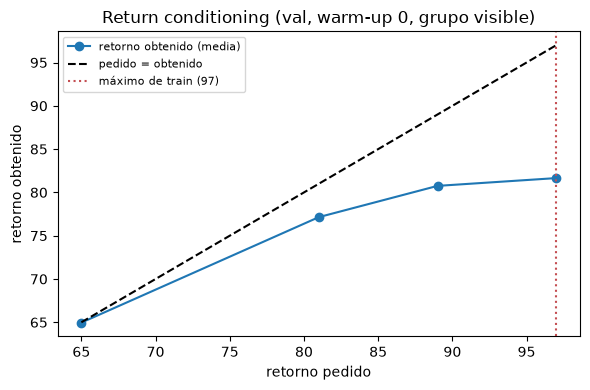

In [13]:
w0_visible = val_dt[(val_dt["warmup"] == 0) & val_dt["visible"]]
mean_return = w0_visible.groupby("target")["return"].mean()
train_max = float(train_ep.returns_to_go()[:, 0].max())

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(mean_return.index, mean_return.values, "o-", label="retorno obtenido (media)")
ax.plot([mean_return.index.min(), train_max], [mean_return.index.min(), train_max], "k--", label="pedido = obtenido")
ax.axvline(train_max, color="#c44e52", ls=":", label=f"máximo de train ({train_max:.0f})")
ax.set_xlabel("retorno pedido")
ax.set_ylabel("retorno obtenido")
ax.set_title("Return conditioning (val, warm-up 0, grupo visible)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. Checklist antes de tocar test

- [ ] La configuración y el retorno se eligieron **sólo con validación**.
- [ ] Se reportan 3 semillas de entrenamiento: media y desvío entre semillas, separados del IC 95 % por usuario.
- [ ] Las líneas base se ajustaron con el mismo split de train.
- [ ] Las curvas de entrenamiento se guardaron sin recortes (no sólo la mejor época).
- [ ] `RUN_TEST = True` se usa **una sola vez**, al final, para la tabla final.

Si además se entrena con logs `mixto` (sección 6 del TP), repetir todo con los logs generados y reajustar las líneas base con esos mismos logs.

In [14]:
if RUN_TEST:
    test = load_test(DATASET)
    frames = []
    for seed, model in models.items():
        policy = DTPolicy(model, target_return=best_target)
        for warmup, visible in conditions:
            cfg = SessionConfig(horizon=HORIZON, warmup=warmup, group_visible=visible)
            df = evaluate(policy, test, N_ITEMS, cfg, seeds=EVAL_SEEDS)
            df["policy"] = f"dt_seed{seed}"
            df["warmup"] = warmup
            df["group_visible"] = visible
            frames.append(df)
    for name, factory in baseline_factories(train, N_ITEMS).items():
        for warmup, visible in conditions:
            cfg = SessionConfig(horizon=HORIZON, warmup=warmup, group_visible=visible)
            df = evaluate(factory(), test, N_ITEMS, cfg, seeds=EVAL_SEEDS)
            df["policy"] = name
            df["warmup"] = warmup
            df["group_visible"] = visible
            frames.append(df)
    test_results = pd.concat(frames, ignore_index=True)
    write_reports(test_results, paths / "eval" / "test")
else:
    print("RUN_TEST=False: test reservado. Cambiarlo a True una sola vez, al final.")

RUN_TEST=False: test reservado. Cambiarlo a True una sola vez, al final.
